In [4]:
from datetime import datetime, timedelta
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rows = [{'id': 1, 'date': '2026-10-18', 'subject': 'Python', 'task': 'Practice for loops', 'minutes': 25, 'completed': 1},
{'id': 2, 'date': '2026-10-18', 'subject': 'Statistics', 'task': 'Read about probability', 'minutes': 40, 'completed': 1},
{'id': 3, 'date': '2026-10-19', 'subject': 'French', 'task': 'Practice listening', 'minutes': 20, 'completed': 1},
{'id': 4, 'date': '2026-10-19', 'subject': 'Python', 'task': 'Build a Tkinter frame', 'minutes': 60, 'completed': 1},
{'id': 5, 'date': '2026-10-20', 'subject': 'Statistics', 'task': 'Practice Bayes theorem', 'minutes': 45, 'completed': 1},
{'id': 6, 'date': '2026-10-20', 'subject': 'French', 'task': 'Review vocabulary', 'minutes': 15, 'completed': 0},
{'id': 7, 'date': '2026-10-21', 'subject': 'Python', 'task': 'Add buttons to study tracker', 'minutes': 35, 'completed': 1},
{'id': 8, 'date': '2026-10-21', 'subject': 'SQL', 'task': 'Learn SELECT queries', 'minutes': 30, 'completed': 1},
{'id': 9, 'date': '2026-10-22', 'subject': 'Statistics', 'task': 'Fit a Poisson model', 'minutes': 55, 'completed': 1},
{'id': 10, 'date': '2026-10-22', 'subject': 'SQL', 'task': 'Practice filtering rows', 'minutes': 25, 'completed': 0},
{'id': 11, 'date': '2026-10-23', 'subject': 'Python', 'task': 'Practice classes', 'minutes': 50, 'completed': 1},
{'id': 12, 'date': '2026-10-23', 'subject': 'French', 'task': 'Read a short article', 'minutes': 20, 'completed': 1},
{'id': 13, 'date': '2026-10-24', 'subject': 'SQL', 'task': 'Create a SQLite database', 'minutes': 30, 'completed': 1},
{'id': 14, 'date': '2026-10-24', 'subject': 'Python', 'task': 'Connect app to database', 'minutes': 45, 'completed': 1},
{'id': 15, 'date': '2026-10-25', 'subject': 'Statistics', 'task': 'Review probability distributions', 'minutes': 30, 'completed': 1},
{'id': 16, 'date': '2026-10-25', 'subject': 'French', 'task': 'Practice speaking', 'minutes': 10, 'completed': 0},
{'id': 17, 'date': '2026-10-26', 'subject': 'Python', 'task': 'Add a completed checkbox', 'minutes': 0, 'completed': 0},
{'id': 18, 'date': '2026-10-26', 'subject': 'SQL', 'task': 'Practice UPDATE statements', 'minutes': 0, 'completed': 0},
{'id': 19, 'date': '2026-10-27', 'subject': 'Statistics', 'task': 'Review logistic regression', 'minutes': 0, 'completed': 0},
{'id': 20, 'date': '2026-10-27', 'subject': 'French', 'task': 'Listen to a French podcast', 'minutes': 0, 'completed': 0},
{'id': 21, 'date': '2026-10-28', 'subject': 'Python', 'task': 'Build a study timer', 'minutes': 0, 'completed': 0},
{'id': 22, 'date': '2026-10-28', 'subject': 'SQL', 'task': 'Practice GROUP BY queries', 'minutes': 0, 'completed': 0},
{'id': 23, 'date': '2026-10-29', 'subject': 'Statistics', 'task': 'Fit a binomial model', 'minutes': 0, 'completed': 0},
{'id': 24, 'date': '2026-10-29', 'subject': 'French', 'task': 'Review verb conjugations', 'minutes': 0, 'completed': 0},
{'id': 25, 'date': '2026-10-30', 'subject': 'Python', 'task': 'Plot weekly study minutes', 'minutes': 0, 'completed': 0},
{'id': 26, 'date': '2026-10-30', 'subject': 'SQL', 'task': 'Calculate totals by subject', 'minutes': 0, 'completed': 0},
{'id': 27, 'date': '2026-10-31', 'subject': 'Statistics', 'task': 'Practice interpreting posteriors', 'minutes': 0, 'completed': 0},
{'id': 28, 'date': '2026-10-31', 'subject': 'French', 'task': 'Read a short story', 'minutes': 0, 'completed': 0},
{'id': 29, 'date': '2026-11-01', 'subject': 'Python', 'task': 'Test the study tracker', 'minutes': 0, 'completed': 0},
{'id': 30, 'date': '2026-11-01', 'subject': 'SQL', 'task': 'Review database queries', 'minutes': 0, 'completed': 0}]

In [8]:
pd.DataFrame(rows).set_index('id').to_dict(orient='index')[1]

{'date': '2026-10-18',
 'subject': 'Python',
 'task': 'Practice for loops',
 'minutes': 25,
 'completed': 1}

In [11]:
import time
print(time.time())

1792980681.8364644


In [151]:
df['subject'].unique().tolist()

['Python', 'Statistics', 'French', 'SQL']

In [152]:
df = pd.DataFrame(todays_items)
subjects = df['subject'].unique().tolist()

today = datetime.today()
yesterday = today - timedelta(1)
start = today - timedelta(8)
last_week = [(start + timedelta(x)).strftime('%A') for x in range(1, 8)]
last_week_dates = [(start + timedelta(x)).strftime('%Y-%m-%d') for x in range(1, 8)]

last_week_data =  (
    df.query('date in @last_week_dates')
      .groupby(['date', 'subject'], as_index = False)[['minutes']]
      .sum()
      .sort_values('date')
)

In [141]:
def get_week_data(subject, last_week_data):
    last_week_dates = [(start + timedelta(x)).strftime('%Y-%m-%d') for x in range(1, 8)]
    date = last_week_data.query(f'subject == "{subject}"')['date'].tolist()
    minutes = last_week_data.query(f'subject == "{subject}"')['minutes'].tolist()

    pointer = 0
    minutes_adjusted = []
    for x in last_week_dates:
        if x in date:
            minutes_adjusted.append(minutes[pointer])
            pointer+=1
        else:
            minutes_adjusted.append(0)
            
    return minutes_adjusted

In [200]:
colors

array([[0.72312188, 0.88961169, 0.69717801, 1.        ],
       [0.15294118, 0.56183007, 0.28313725, 1.        ],
       [0.        , 0.32719723, 0.13098039, 1.        ],
       [0.42666667, 0.75478662, 0.44890427, 1.        ]])

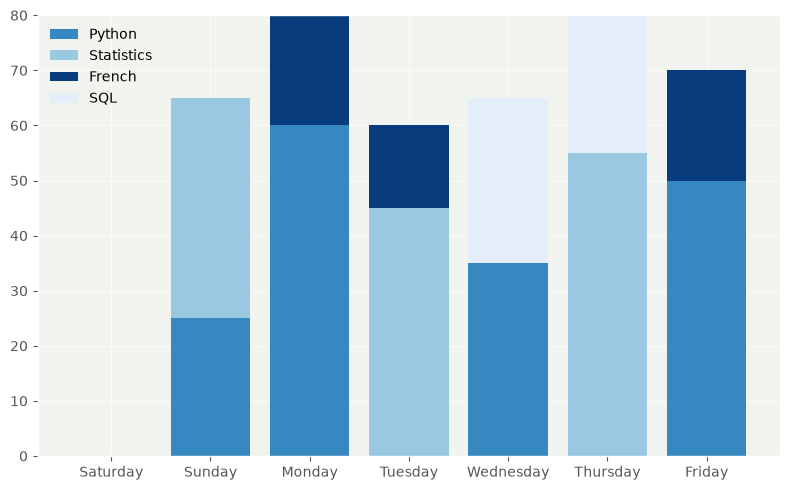

In [205]:
plt.style.use('ggplot')

fig, ax = plt.subplots(figsize=(8, 5))
last_week_array = np.array(last_week)

ax.set_facecolor("#F1F4EE")

cmap = plt.get_cmap("Blues")
colors = cmap(np.linspace(0.1, 0.95, len(subjects)))
np.random.default_rng().shuffle(colors)
bottom = np.zeros(len(last_week_array))

for i, subject in enumerate(subjects):
    subject_minutes = np.array(get_week_data(subject, last_week_data))

    ax.bar(
        last_week_array,
        subject_minutes,
        bottom=bottom,
        label=subject,
        color=colors[i],
    )

    bottom += subject_minutes

ax.legend(frameon=False)
plt.tight_layout()
plt.show()

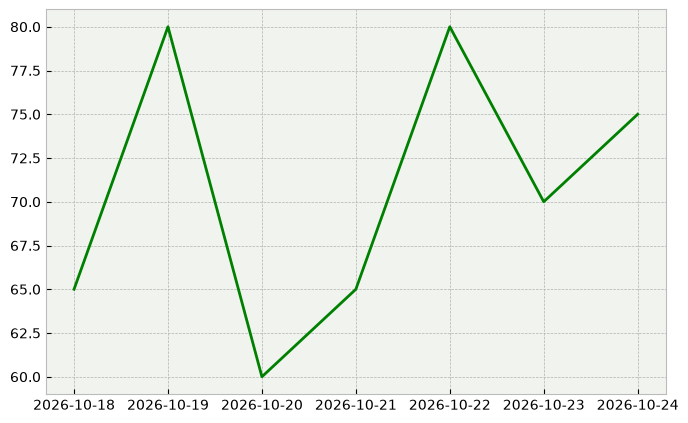

In [202]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_facecolor("#F1F4EE")

df_grouped = df.groupby('date', as_index=False)[['minutes']].sum()

dates=df_grouped['date']
minutes=df_grouped['minutes']

ax.plot(dates,minutes, color='g')